In [13]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from pydantic import BaseModel, Field
from dotenv import load_dotenv
from langchain_groq import ChatGroq

from langgraph.checkpoint.memory import InMemorySaver

In [14]:
load_dotenv()

model = ChatGroq(model="openai/gpt-oss-120b",  # Or use "qwen/qwen3.8-27b"
    temperature=0)

In [ ]:
class ChatbotState(TypedDict):
    topic: str
    joke: str
    explanation: str

In [26]:
graph = StateGraph(ChatbotState)

In [17]:
def generate_joke(state: ChatbotState) -> ChatbotState:
    prompt = f"Generate a joke about {state['topic']}"
    joke = model.invoke(prompt).content
    return {'joke': joke}


def explain_joke(state: ChatbotState) -> ChatbotState:
    prompt = f"Explain the joke: {state['joke']}"
    explanation = model.invoke(prompt).content
    return {'explanation': explanation}

In [27]:
graph.add_node('generate_joke', generate_joke)
graph.add_node('explain_joke', explain_joke)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'explain_joke')
graph.add_edge('explain_joke', END)

checkpoint_saver = InMemorySaver()

workflow = graph.compile(checkpointer = checkpoint_saver )

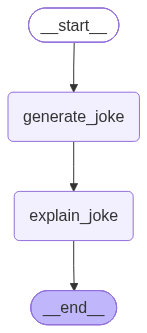

In [28]:
workflow

In [30]:
config1 = {"configurable": {"thread_id":"1"}}
initial_state = {"topic": "programming"}
workflow.invoke(initial_state, config=config1)

{'topic': 'programming',
 'joke': 'Why do programmers prefer dark mode?\n\nBecause light attracts bugs!',
 'explanation': '**Short answer:**  \nThe joke plays on the double meaning of the word **“bugs.”** In the natural world, insects (bugs) are drawn to light sources, so “light attracts bugs.” In software development, a “bug” is an error or flaw in a program. By saying that “light attracts bugs,” the joke pretends that turning on a light‑based (bright) UI would literally draw more software errors, so programmers “prefer dark mode” to keep the bugs away.\n\n---\n\n## 1. The two meanings of “bug”\n\n| Context | Meaning of “bug” | Why it matters |\n|---------|------------------|----------------|\n| **Nature / everyday life** | An insect (e.g., moth, beetle). Many insects are phototactic – they fly toward light sources at night. | The phrase “light attracts bugs” is a factual observation. |\n| **Software engineering** | A defect, mistake, or unintended behavior in code. The term dates bac

In [33]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'programming', 'joke': 'Why do programmers prefer dark mode?\n\nBecause light attracts bugs!', 'explanation': '**Short answer:**  \nThe joke plays on the double meaning of the word **“bugs.”** In the natural world, insects (bugs) are drawn to light sources, so “light attracts bugs.” In software development, a “bug” is an error or flaw in a program. By saying that “light attracts bugs,” the joke pretends that turning on a light‑based (bright) UI would literally draw more software errors, so programmers “prefer dark mode” to keep the bugs away.\n\n---\n\n## 1. The two meanings of “bug”\n\n| Context | Meaning of “bug” | Why it matters |\n|---------|------------------|----------------|\n| **Nature / everyday life** | An insect (e.g., moth, beetle). Many insects are phototactic – they fly toward light sources at night. | The phrase “light attracts bugs” is a factual observation. |\n| **Software engineering** | A defect, mistake, or unintended behavior in code